In [57]:
# Imports
import math
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import numpy as np
from scipy import stats
import seaborn as sns
import matplotlib


In [58]:
#Getting the Average success values from the Rag and No Rag runs
df = pd.read_csv('oneshot/vitis_oneshot1.csv')
df2 = pd.read_csv('oneshot/vitis_oneshot2.csv')
df_dyna = pd.read_csv('oneshot/dynarapid_oneshot.csv')

# Formatting the successes and model names
df['latency'] = pd.to_numeric(df['latency'], errors='coerce')
df['model'] = df['model'].str.split('/').str[-1]
df2['latency'] = pd.to_numeric(df2['latency'], errors='coerce')
df2['model'] = df2['model'].str.split('/').str[-1]

df['compilation_failed'] = df['compilation_status'] == 'failed'
df['mismatched_only'] = (df['outputs_match'] == 'mismatch') & (df['compilation_status'] != 'failed')
df2['compilation_failed'] = df2['compilation_status'] == 'failed'
df2['mismatched_only'] = (df2['outputs_match'] == 'mismatch') & (df2['compilation_status'] != 'failed')

# print(df)
df_dyna['model'] = df_dyna['model'].str.split('/').str[-1]
df_dyna['has_dot'] = pd.to_numeric(df_dyna['has_dot'], errors='coerce')
df_dyna['has_dcp'] = pd.to_numeric(df_dyna['has_dcp'], errors='coerce')
df_dyna['compilation_failed'] = (df_dyna['compiled'] == 'failed').astype(int)
df_dyna['mismatched_only'] = ((df_dyna['matched'] == 'mismatch') & (df_dyna['compiled'] != 'failed')).astype(int)
df_dyna['csim_passed'] = (df_dyna['matched'] == 'match') & (df_dyna['compiled'] != 'failed').astype(int)

#Getting success Rates
success_cnts_unsort = df.groupby(['model', 'RAG'])['csim_success'].sum()
success_counts = df.groupby(['model', 'RAG'])['csim_success'].sum().sort_values(ascending=False)
total_tests = 101
success1 = (success_counts / total_tests) * 100
success1_unsort = (success_cnts_unsort / total_tests) * 100

success_cnts_unsort = df2.groupby(['model', 'RAG'])['csim_success'].sum()
success_counts = df2.groupby(['model', 'RAG'])['csim_success'].sum().sort_values(ascending=False)
total_tests = 101
success2 = (success_counts / total_tests) * 100
success2_unsort = (success_cnts_unsort / total_tests) * 100

average_success = (success1 + success2) /2
average_success_unsort = (success1_unsort + success2_unsort) /2

average_success = average_success.reset_index(name='csim_success')

#Averaging the success rates
# print(average_success_unsort)
# print(avg_success_norag)

#Get Average Price per Call in each Rag v NoRag run
model_costs_data_norag = {
    'model': ['gemini-2.5-flash', 'deepseek-chat-v3-0324', 'deepseek-r1-0528', 'gpt-4.1-mini', 'grok-code-fast-1',  
              'qwen3-coder', 'gpt-5', 'grok-4', 'gemini-2.5-pro', 'claude-sonnet-4.5'],
    'Base_Cost_Per_Run': [0.25, 0.08, 0.88, 0.12, 0.15, 0.08, 2.66, 6.07, 4.48, 1.92],
    'Cost_STD': [0.16, 0.05, 0.46, 0.06, 0.06, 0.07, 1.05, 4.12, 2.61, 1.16]
}
costs_norag = pd.DataFrame(model_costs_data_norag).set_index('model')

model_costs_data_rag = {
    'model': ['gemini-2.5-flash', 'deepseek-chat-v3-0324', 'deepseek-r1-0528', 'gpt-4.1-mini', 'grok-code-fast-1',  
              'qwen3-coder', 'gpt-5', 'grok-4', 'gemini-2.5-pro', 'claude-sonnet-4.5'],
    'Base_Cost_Per_Run': [0.22, 0.12, 0.92, 0.17, 0.18, 0.09, 2.93, 7.90, 6.13, 1.92]
}
costs_rag = pd.DataFrame(model_costs_data_rag).set_index('model')


# costs_rag.rename(columns={'Model': 'model'}, inplace=True)
# costs_norag.rename(columns={'Model': 'model'}, inplace=True)

avg_success_rag = average_success[average_success['RAG'] == 'rag'].copy()
avg_success_norag = average_success[average_success['RAG'] == 'no_rag'].copy()

plot_df_rag = avg_success_rag.merge(
    costs_rag, 
    on='model', 
    how='left'
).rename(columns={'Base_Cost_Per_Run': 'Cost_Per_Run'})
plot_df_norag = avg_success_norag.merge(
    costs_norag, 
    on='model', 
    how='left'
).rename(columns={'Base_Cost_Per_Run': 'Cost_Per_Run'})

# 4. Combine RAG and No RAG data into the final plotting DataFrame
final_plot_df = pd.concat([plot_df_rag, plot_df_norag], ignore_index=True)

# 5. Clean up final columns: rename csim_success for clarity
final_plot_df.rename(
    columns={'csim_success': 'Average Success Rate (%)'}, 
    inplace=True
)

plot_df_norag.rename(
    columns={'csim_success': 'Average Success Rate (%)'}, 
    inplace=True
)

# print("\nFinal Plotting DataFrame ready (final_plot_df):")
# print(plot_df_norag)
print(df_dyna)


            model    rag                      kernel  run  attempt compiled  \
0    gpt-4.1-mini  False       scale_matrix_3d_int32    1        1   passed   
1    gpt-4.1-mini  False        maxpool2d_relu_int32    1        1   passed   
2    gpt-4.1-mini  False                conv2d_int32    1        1   passed   
3    gpt-4.1-mini  False                argmax_int32    1        1   passed   
4    gpt-4.1-mini  False       elementwise_min_int32    1        1   passed   
..            ...    ...                         ...  ...      ...      ...   
295         gpt-5  False            compare_lt_int32    1        1   passed   
296         gpt-5  False       reduce_add_relu_int32    1        1   passed   
297         gpt-5  False  dotproduct_bias_relu_int32    1        1   passed   
298         gpt-5  False            maxpool1d_uint32    1        1   failed   
299         gpt-5  False                conv1d_int32    1        1   passed   

      matched  has_dot  has_dcp        llm_time    

In [59]:
success_dcp = df_dyna.groupby(['model'])['has_dcp'].sum()
rates_dcp = success_dcp / 30 * 100

success_dot = df_dyna.groupby('model')['has_dot'].sum()
rates_dot = success_dot / 30 * 100

print(rates_dcp)

model
claude-sonnet-4.5        43.333333
deepseek-chat-v3-0324    46.666667
deepseek-r1-0528         43.333333
gemini-2.5-flash          6.666667
gemini-2.5-pro           43.333333
gpt-4.1-mini             46.666667
gpt-5                    40.000000
grok-4                   30.000000
grok-code-fast-1         43.333333
qwen3-coder              43.333333
Name: has_dcp, dtype: float64


In [60]:

# Analyze kernel failure patterns per model
# Combine both runs for comprehensive analysis
df_combined = pd.concat([df, df2], ignore_index=True)

# Ensure columns exist and are numeric
df_combined['csim_success'] = pd.to_numeric(df_combined['csim_success'], errors='coerce')
df_combined['csynth_success'] = pd.to_numeric(df_combined['csynth_success'], errors='coerce')

# Create failure categories
df_combined['both_fail'] = ((df_combined['csim_success'] == 0) & (df_combined['csynth_success'] == 0)).astype(int)
df_combined['csynth_fail_csim_pass'] = ((df_combined['csim_success'] == 1) & (df_combined['csynth_success'] == 0)).astype(int)

# Group by model and RAG to get counts and percentages
failure_analysis = df_combined.groupby(['model', 'RAG']).agg(
    total_tests=('model', 'count'),
    both_fail_count=('both_fail', 'sum'),
    fail_compilation= ('compilation_failed', 'sum'),
    mismatched= ('mismatched_only', 'sum'),
    csynth_fail_csim_pass_count=('csynth_fail_csim_pass', 'sum')
).reset_index()

# Calculate percentages
failure_analysis['both_fail_pct'] = (failure_analysis['both_fail_count'] / failure_analysis['total_tests']) * 100
failure_analysis['fail_compilation_pct'] = (failure_analysis['fail_compilation'] / failure_analysis['total_tests']) * 100
failure_analysis['mismatched_pct'] = (failure_analysis['mismatched'] / failure_analysis['total_tests']) * 100

failure_analysis['csynth_fail_csim_pass_pct'] = (failure_analysis['csynth_fail_csim_pass_count'] / failure_analysis['total_tests']) * 100

# Clean up model names
failure_analysis['model'] = failure_analysis['model'].str.split('/').str[-1]

# Display results
# print("\n=== Kernel Failure Analysis by Model ===\n")
# print(failure_analysis.to_string(index=False))


                    model     RAG  csim_success
0       claude-sonnet-4.5  no_rag     89.108911
2   deepseek-chat-v3-0324  no_rag     67.326733
4        deepseek-r1-0528  no_rag     66.831683
6        gemini-2.5-flash  no_rag     74.257426
8          gemini-2.5-pro  no_rag     59.405941
10           gpt-4.1-mini  no_rag     73.762376
12                  gpt-5  no_rag     77.227723
14                 grok-4  no_rag     80.693069
16       grok-code-fast-1  no_rag     71.782178
18            qwen3-coder  no_rag     80.198020


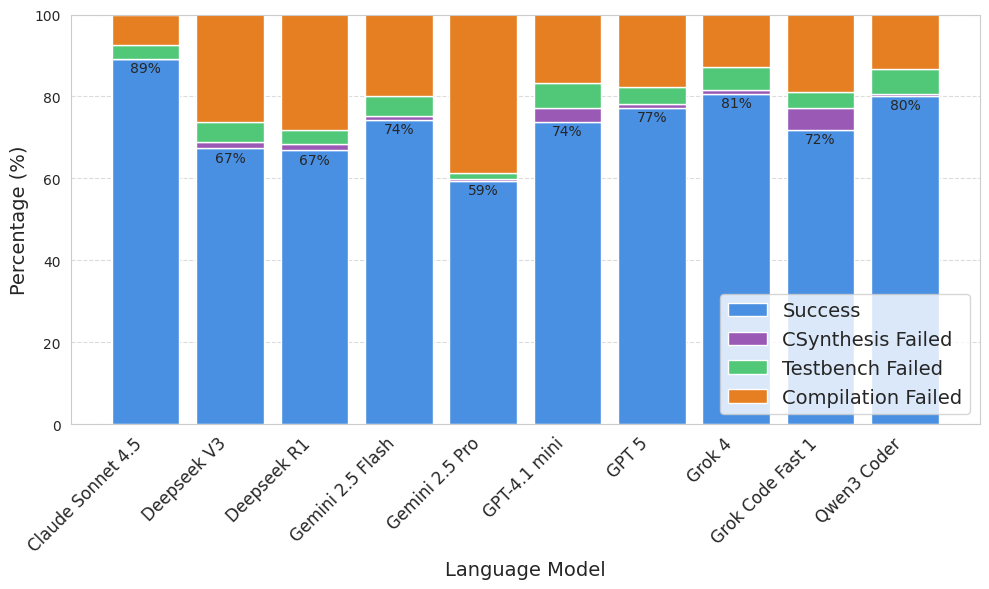

In [61]:
# Creating the Plots with failure breakdown stacked on top of success
# Filter failure analysis for no_rag only
failure_norag = failure_analysis[failure_analysis['RAG'] == 'no_rag'].copy()

# Get success rate data for no_rag
df_plot_norag = average_success_unsort.reset_index(name='csim_success')
df_plot_norag = df_plot_norag[df_plot_norag['RAG'] == 'no_rag'].copy()
print(df_plot_norag)

# Rename models for better display
model_names = {
    "gpt-4.1-mini": "GPT-4.1 mini",
    "grok-code-fast-1": "Grok Code Fast 1",
    "gemini-2.5-flash": "Gemini 2.5 Flash",
    "deepseek-chat-v3-0324": "Deepseek V3",
    "deepseek-r1-0528": "Deepseek R1",
    "qwen3-coder": "Qwen3 Coder",
    "grok-4": "Grok 4",
    "gemini-2.5-pro": "Gemini 2.5 Pro",
    "claude-sonnet-4.5": "Claude Sonnet 4.5",
    "gpt-5": "GPT 5"
}

# Merge failure data with success rates
failure_norag['model'] = failure_norag['model'].map(model_names)
df_plot_norag['model'] = df_plot_norag['model'].map(model_names)

# Merge on model name to align data
merged_data = pd.merge(df_plot_norag, failure_norag, on='model', how='left')
merged_data = merged_data.set_index('model')

# --- Visualization ---
plt.figure(figsize=(10, 6))

# Create stacked bar chart: Blue (success) + Green (csynth fail) + Orange (both fail)
x = range(len(merged_data))
success_pct = merged_data['csim_success'].values
csynth_fail_pct = merged_data['csynth_fail_csim_pass_pct'].values
both_fail_pct = merged_data['both_fail_pct'].values
compile_fail_pct = merged_data['fail_compilation_pct'].values
mismatched_pct = merged_data['mismatched_pct']

p1 = plt.bar(x, success_pct, label='Success', color="#4A90E2")
p2 = plt.bar(x, csynth_fail_pct, bottom=success_pct, label='CSynthesis Failed', color="#9B59B6")
p3 = plt.bar(x, mismatched_pct, bottom=success_pct + csynth_fail_pct, label='Testbench Failed', color='#50C878')
p4 = plt.bar(x, compile_fail_pct, bottom=success_pct + csynth_fail_pct+ mismatched_pct, label='Compilation Failed', color="#E67E22")

for rect, v in zip(p1, success_pct):
    height = rect.get_height()
    plt.text(
        rect.get_x() + rect.get_width() / 2,
        height - 4,
        f"{v:.0f}%",
        ha='center',
        va='bottom',
        fontsize=10
    )


# Add title and labels
# plt.title(f'Pass and Fail Rates', fontsize=14)
plt.ylabel('Percentage (%)', fontsize=14)
plt.xlabel('Language Model', fontsize=14)
plt.ylim(0, 100)
plt.xticks(x, merged_data.index, rotation=45, ha='right', fontsize=12)
plt.legend(loc='lower right', fontsize=14)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig("success_fail_rates.pdf", dpi=300, bbox_inches='tight')   
plt.show()


In [62]:
# Failure Analysis for Dynarapid


df_combined = df_dyna

# Ensure columns exist and are numeric
df_combined['implement_success'] = pd.to_numeric(df_combined['has_dcp'], errors='coerce')
df_combined['csynth_success'] = pd.to_numeric(df_combined['has_dot'], errors='coerce')
df_combined['success'] = ((df_combined['csynth_success'] == 1) & (df_combined['implement_success'] == 1)).astype(int)
df_combined['failed_implement'] = ((df_combined['implement_success'] == 0) & (df_combined['csynth_success'] == 1)).astype(int)
df_combined['failed_csynth'] = ((df_combined['csim_passed'] == 1) & (df_combined['csynth_success'] == 0)).astype(int)

# Create failure categories

# Group by model and RAG to get counts and percentages
failure_analysis = df_combined.groupby(['model', 'rag']).agg(
    total_tests=('model', 'count'),
    fail_compilation= ('compilation_failed', 'sum'),
    mismatched= ('mismatched_only', 'sum'),
    failed_csynth=('failed_csynth', 'sum'),
    failed_implement=('failed_implement', 'sum'),
    success=('implement_success', 'sum')
).reset_index()
# Calculate percentages
failure_analysis['failed_csynth_pct'] = (failure_analysis['failed_csynth'] / failure_analysis['total_tests']) * 100
failure_analysis['failed_implement_pct'] = (failure_analysis['failed_implement'] / failure_analysis['total_tests']) * 100
failure_analysis['fail_compilation_pct'] = (failure_analysis['fail_compilation'] / failure_analysis['total_tests']) * 100
failure_analysis['mismatched_pct'] = (failure_analysis['mismatched'] / failure_analysis['total_tests']) * 100
failure_analysis['success_pct'] = (failure_analysis['success'] / failure_analysis['total_tests']) * 100


# Clean up model names
failure_analysis['model'] = failure_analysis['model'].str.split('/').str[-1]

# Display results
# print("\n=== Kernel Failure Analysis by Model ===\n")
# failure_analysis = failure_analysis.set_index('model')
print(failure_analysis.to_string(index=False))

                model   rag  total_tests  fail_compilation  mismatched  failed_csynth  failed_implement  success  failed_csynth_pct  failed_implement_pct  fail_compilation_pct  mismatched_pct  success_pct
    claude-sonnet-4.5 False           30                 1           1              4                11       13          13.333333             36.666667              3.333333        3.333333    43.333333
deepseek-chat-v3-0324 False           30                 1           0              5                10       14          16.666667             33.333333              3.333333        0.000000    46.666667
     deepseek-r1-0528 False           30                 5           0              4                 8       13          13.333333             26.666667             16.666667        0.000000    43.333333
     gemini-2.5-flash False           30                23           0              5                 0        2          16.666667              0.000000             76.666667     

                   model    rag  total_tests  fail_compilation  mismatched  \
0      claude-sonnet-4.5  False           30                 1           1   
1  deepseek-chat-v3-0324  False           30                 1           0   
2       deepseek-r1-0528  False           30                 5           0   
3       gemini-2.5-flash  False           30                23           0   
4         gemini-2.5-pro  False           30                 1           0   
5           gpt-4.1-mini  False           30                 1           0   
6                  gpt-5  False           30                 2           0   
7                 grok-4  False           30                 3           0   
8       grok-code-fast-1  False           30                 1           0   
9            qwen3-coder  False           30                 2           0   

   failed_csynth  failed_implement  success  failed_csynth_pct  \
0              4                11       13          13.333333   
1        

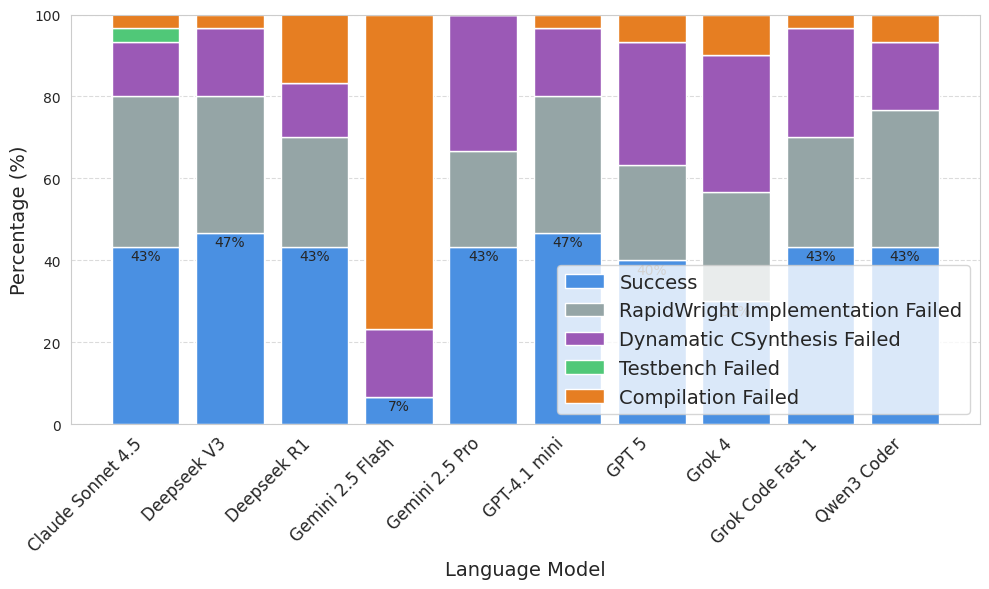

In [63]:
# Creating the Plots with failure breakdown stacked on top of success
# Filter failure analysis for no_rag only

# Get success rate data for no_rag

print(failure_analysis)
# Rename models for better display
model_names = {
    "gpt-4.1-mini": "GPT-4.1 mini",
    "grok-code-fast-1": "Grok Code Fast 1",
    "gemini-2.5-flash": "Gemini 2.5 Flash",
    "deepseek-chat-v3-0324": "Deepseek V3",
    "deepseek-r1-0528": "Deepseek R1",
    "qwen3-coder": "Qwen3 Coder",
    "grok-4": "Grok 4",
    "gemini-2.5-pro": "Gemini 2.5 Pro",
    "claude-sonnet-4.5": "Claude Sonnet 4.5",
    "gpt-5": "GPT 5"
}

# Merge failure data with success rates
failure_analysis['model'] = failure_analysis['model'].map(model_names)

failure_analysis = failure_analysis.set_index('model')
# --- Visualization ---
plt.figure(figsize=(10, 6))

# Create stacked bar chart: Blue (success) + Green (csynth fail) + Orange (both fail)
x = range(len(failure_analysis))
success_pct = failure_analysis['success_pct'].values
csynth_fail_pct = failure_analysis['failed_csynth_pct'].values
implement_fail_pct = failure_analysis['failed_implement_pct'].values
compile_fail_pct = failure_analysis['fail_compilation_pct'].values
mismatched_pct = failure_analysis['mismatched_pct'].values
# print(success_pct, csynth_fail_pct, implement_fail_pct, compile_fail_pct, mismatched_pct)

p1 = plt.bar(x, success_pct, label='Success', color="#4A90E2")
p2 = plt.bar(x, implement_fail_pct, bottom=success_pct, label='RapidWright Implementation Failed', color="#95A5A6")
p3 = plt.bar(x, csynth_fail_pct, bottom=success_pct+implement_fail_pct, label='Dynamatic CSynthesis Failed', color="#9B59B6")
p4 = plt.bar(x, mismatched_pct, bottom=success_pct + csynth_fail_pct+implement_fail_pct, label='Testbench Failed', color='#50C878')
p5 = plt.bar(x, compile_fail_pct, bottom=success_pct + csynth_fail_pct+ mismatched_pct+implement_fail_pct, label='Compilation Failed', color="#E67E22")

for rect, v in zip(p1, success_pct):
    height = rect.get_height()
    plt.text(
        rect.get_x() + rect.get_width() / 2,
        height - 4,
        f"{v:.0f}%",
        ha='center',
        va='bottom',
        fontsize=10
    )

# Add title and labels
# plt.title(f'Pass and Fail Rates', fontsize=14)
plt.ylabel('Percentage (%)', fontsize=14)
plt.xlabel('Language Model', fontsize=14)
plt.ylim(0, 100)
plt.xticks(x, failure_analysis.index, rotation=45, ha='right', fontsize = 12)
plt.legend(loc='lower right', fontsize=14)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig("success_fail_rates_dynarapid.pdf", dpi=300, bbox_inches='tight')   
plt.show()


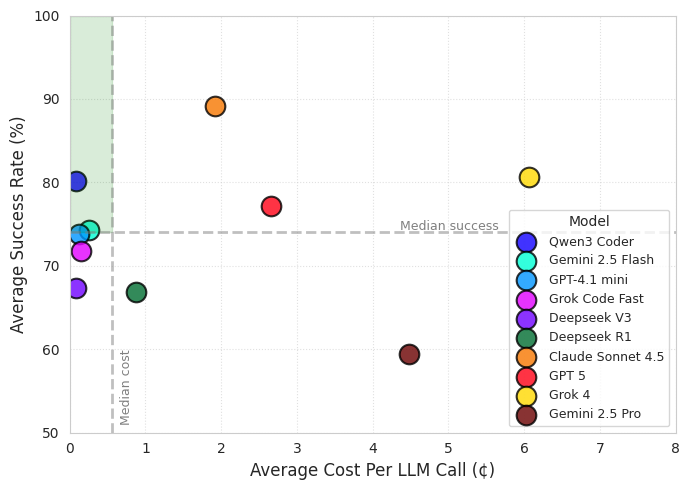

In [64]:
# Getting the updated cost per success model with model colors

final_plot_df_filtered = plot_df_norag

# Define expensive models
expensive_models = {'claude-sonnet-4.5', 'gemini-2.5-pro', 'gpt-5', 'grok-4'}

# Add a category column
final_plot_df_filtered['category'] = final_plot_df_filtered['model'].apply(
    lambda x: 'Expensive' if x in expensive_models else 'Cheaper'
)


# Define display names
model_names = {
    "gpt-4.1-mini": "GPT-4.1 mini",
    "grok-code-fast-1": "Grok Code Fast",
    "gemini-2.5-flash": "Gemini 2.5 Flash",
    "deepseek-chat-v3-0324": "Deepseek V3",
    "deepseek-r1-0528": "Deepseek R1",
    "qwen3-coder": "Qwen3 Coder",
    "grok-4": "Grok 4",
    "gemini-2.5-pro": "Gemini 2.5 Pro",
    "claude-sonnet-4.5": "Claude Sonnet 4.5",
    "gpt-5": "GPT 5"
}
final_plot_df_filtered['model_display'] = final_plot_df_filtered['model'].map(model_names)

# cheap_df = final_plot_df_filtered[final_plot_df_filtered['category']=='Cheaper']
# expensive_df = final_plot_df_filtered[final_plot_df_filtered['category']=='Expensive']


# Create scatter plot with different color for each model
colors_map = {
    "gpt-4.1-mini": "#0095ff",
    "grok-code-fast-1": "#e100ff",
    "gemini-2.5-flash": "#00ffd5",
    "deepseek-chat-v3-0324": "#6f00ff",
    "deepseek-r1-0528": "#006d31",
    "qwen3-coder": "#1100ff",
    "grok-4": "#ffd900",
    "gemini-2.5-pro": "#6b0000",
    "claude-sonnet-4.5": "#f77700",
    "gpt-5": "#ff0015"
}

# Define the model order (same as colors_map order)
model_order = [
    "qwen3-coder",
    "gemini-2.5-flash",
    "gpt-4.1-mini",
    "grok-code-fast-1",
    "deepseek-chat-v3-0324",
    "deepseek-r1-0528",
    "claude-sonnet-4.5",
    "gpt-5",
    "grok-4",
    "gemini-2.5-pro",
]

# Plotting helper
def plot_group(df, title):
    fig, ax = plt.subplots(figsize=(7, 5))
    sns.set_style("whitegrid")

    models_in_order = [m for m in model_order if m in df['model'].values]
    for model in models_in_order:
        model_data = df[df['model'] == model]
        if len(model_data) == 0:
            continue
        ax.scatter(
            model_data['Cost_Per_Run'],
            model_data['Average Success Rate (%)'],
            s=200,
            alpha=0.8,
            color=colors_map.get(model, '#000000'),
            label=model_names.get(model, model),
            edgecolors='black',
            linewidth=1.5
        )
        cost = model_data['Cost_Per_Run'].values
        succ = model_data['Average Success Rate (%)'].values
        cost_std = model_data['Cost_STD'].values


        # ax.errorbar(
        #     cost, succ,
        #     xerr=cost_std,
        #     fmt='o',
        #     color=colors_map.get(model, '#000000'),
        #     ecolor='gray',
        #     elinewidth=2,
        #     capsize=6,
        #     alpha=0.9
        # )

    # Median lines (no legend entries)
    if len(df) > 0:
        median_cost = df['Cost_Per_Run'].median()
        median_success = df['Average Success Rate (%)'].median()
        ax.axhline(median_success, color='gray', linestyle='--', alpha=0.5, linewidth=2)
        ax.axvline(median_cost, color='gray', linestyle='--', alpha=0.5, linewidth=2)

        # Label horizontal median (slightly to the right)
        ax.text(
            median_cost + 3.8, median_success + 0.3,
            'Median success',
            color='gray',
            fontsize=9
        )

        # Label vertical median (slightly above)
        ax.text(
            median_cost + 0.1, median_success - 14,
            'Median cost',
            rotation=90,
            color='gray',
            fontsize=9,
            va='top'
        )
        ax.set_xlim(0, 8)
        ax.set_ylim(50, 100)
        ymin, ymax = ax.get_ylim()

        ax.fill_between(
            [0, median_cost],
            median_success,
            ymax,
            color='green',
            alpha=0.15
        )

        # ax.text(
        #     median_cost * 0.3,              # somewhere in that shaded region
        #     median_success + 0.5*(ax.get_ylim()[1]-median_success),
        #     'Ideal region:\nlow cost, high success',
        #     fontsize=9,
        #     color='darkgreen',
        #     ha='center',
        #     va='center',
        #     bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.7)
        # )

    # ax.set_title(title, fontsize=14, fontweight='bold')
    ax.set_xlabel('Average Cost Per LLM Call (¢)', fontsize=12)
    ax.set_ylabel('Average Success Rate (%)', fontsize=12)
    ax.set_xlim(0, 8)
    ax.set_ylim(50, 100)
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.legend(title='Model', loc='lower right', fontsize=9, title_fontsize=10, ncol=1)
    plt.tight_layout()
    plt.savefig("success_v_cost.pdf", dpi=300, bbox_inches='tight')   
    plt.show()
    

# Generate two separate figures
plot_group(final_plot_df_filtered, 'Success Rate vs. Base Cost')
# plot_group(expensive_df, 'Expensive Models — Success Rate vs. Base Cost')

